# Inflación: tendencia, mercado y pronósticos

Tres preguntas que la variación anual del INPC no contesta por sí sola:

1. **¿Hacia dónde va?** — medidas de tendencia, la estimación anticipada del mes y qué componentes la empujan.
2. **¿Qué espera el mercado?** — inflación implícita en Bonos M y Udibonos, y la curva de rendimientos.
3. **¿Qué diría un modelo sencillo?** — pronósticos de referencia, evaluados fuera de muestra.

El token no aparece en el notebook: `banxicolab` lo toma del entorno (ver la documentación).

In [1]:
# Instala la librería solo si hace falta (por ejemplo, en Google Colab)
try:
    import banxicolab
except ImportError:
    %pip install -q banxicolab

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import banxicolab as sie

GUINDA, TEAL, OCRE, GRIS = '#800020', '#0F7173', '#C9A227', '#646464'
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.color': '#EDEDED',
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
                     'legend.frameon': False})

bmx = sie.Banxico(cache="disco")  # las descargas se guardan: re-ejecutar no gasta consultas
INICIO = '2005-01-01'

## 1. ¿Hacia dónde va? Medidas de tendencia

La inflación anual compara con hace doce meses, así que arrastra lo que pasó hace un año. Tres
lecturas complementarias:

- **Subyacente**: excluye agropecuarios, energéticos y tarifas, que son volátiles.
- **Media truncada** (calculada por Banxico): descarta cada mes los genéricos con las variaciones
  más extremas, sean los que sean.
- **Impulso 3m/3m**: promedio de los últimos tres meses contra los tres previos, desestacionalizado
  y anualizado. Reacciona meses antes que la anual.

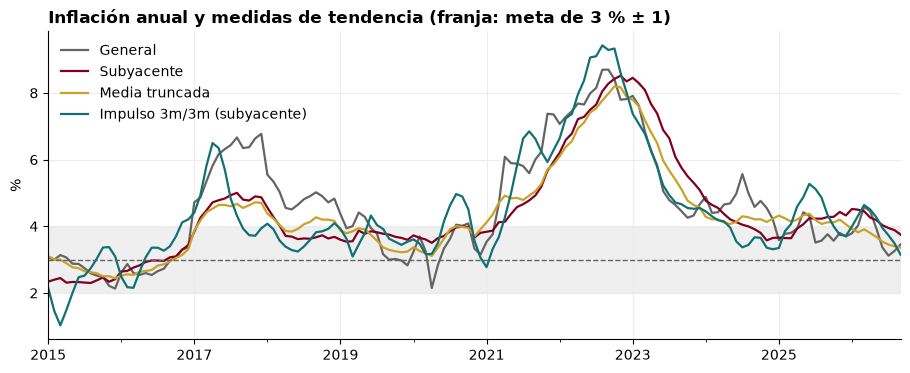

,General,Subyacente,Media truncada,Impulso 3m/3m (subyacente)
fecha,,,,
2026-04-01,4.45,4.26,3.80,4.50
2026-05-01,3.94,4.19,3.68,4.27
2026-06-01,3.37,4.03,3.54,3.95
2026-07-01,3.12,3.95,3.45,3.73
2026-08-01,3.26,3.88,3.40,3.48
2026-09-01,3.45,3.75,3.36,3.14


In [3]:
indices = bmx.descargar(['inpc', 'inpc_subyacente'], INICIO)
truncada = bmx.serie('media_truncada', INICIO)

tendencia = pd.DataFrame({
    'General'           : sie.variacion_anual(indices['inpc']),
    'Subyacente'        : sie.variacion_anual(indices['inpc_subyacente']),
    'Media truncada'    : truncada,
    'Impulso 3m/3m (subyacente)': sie.impulso(indices['inpc_subyacente'], 3),
}).loc['2015':]

ax = tendencia.plot(color=[GRIS, GUINDA, OCRE, TEAL], lw=1.6)
ax.axhspan(2, 4, color=GRIS, alpha=.10)
ax.axhline(3, color=GRIS, ls='--', lw=1)
ax.set_title('Inflación anual y medidas de tendencia (franja: meta de 3 % ± 1)')
ax.set_ylabel('%'); ax.set_xlabel('')
plt.show()

tendencia.dropna().tail(6).round(2)

### Persistencia

La suma de los coeficientes de un AR(12) sobre la inflación mensual desestacionalizada mide cuánto
tardan en disiparse los choques: cerca de 0 se revierten pronto, cerca de 1 se quedan. Estimada en
ventanas móviles de diez años muestra si la inflación se ha vuelto más o menos persistente.

Persistencia de la subyacente, muestra completa: 0.83


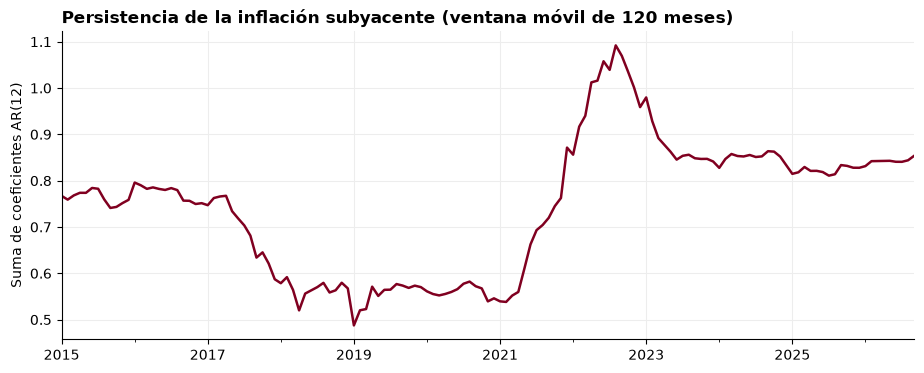

In [4]:
mensual_sa = sie.variacion(sie.desestacionalizar(indices['inpc_subyacente']))

print(f'Persistencia de la subyacente, muestra completa: {sie.persistencia(mensual_sa):.2f}')

ax = sie.persistencia(mensual_sa, ventana=120).plot(color=GUINDA, lw=1.8)
ax.set_title('Persistencia de la inflación subyacente (ventana móvil de 120 meses)')
ax.set_ylabel('Suma de coeficientes AR(12)'); ax.set_xlabel('')
plt.show()

### El mes antes de que se publique

El INPC mensual es el promedio de sus dos quincenas, y la primera quincena se publica unos quince días antes
que el dato mensual. `anticipar_inflacion` estima la segunda quincena con el comportamiento de ese mismo mes en
los ocho años anteriores. El rango va del año de referencia más bajo al más alto.

In [5]:
try:
    display(bmx.anticipar_inflacion().round(2))
except ValueError as aviso:   # el mes más reciente ya tiene sus dos quincenas
    print(aviso)

,primera_quincena,mensual,mensual_inf,mensual_sup,anual,anual_inf,anual_sup
mes,,,,,,,
2026-10-01,146.74,0.53,0.52,0.65,3.63,3.62,3.75


¿Qué tan confiable es? Repetimos la estimación para cada mes desde 2012, usando solo lo que se sabía en su
momento, y la comparamos con lo que después publicó INEGI.

Meses evaluados: 177
Error típico en la inflación mensual: 0.09 puntos porcentuales
El dato observado cayó dentro del rango en 77% de los meses


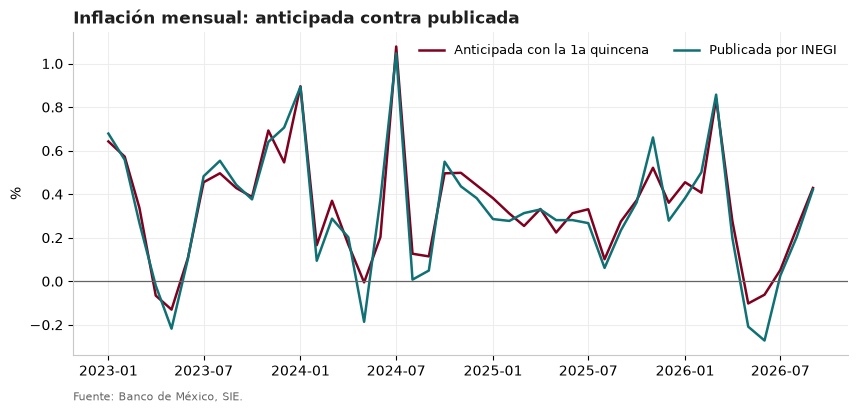

In [6]:
historial = bmx.anticipar_inflacion(historial=True).loc["2012":]
error = historial["mensual"] - historial["mensual_observada"]
dentro = historial["mensual_observada"].between(historial["mensual_inf"], historial["mensual_sup"])
print(f"Meses evaluados: {len(historial)}")
print(f"Error típico en la inflación mensual: {(error**2).mean()**0.5:.2f} puntos porcentuales")
print(f"El dato observado cayó dentro del rango en {dentro.mean():.0%} de los meses")

sie.graficar(historial.loc["2023":, ["mensual", "mensual_observada"]].rename(
    columns={"mensual": "Anticipada con la 1a quincena", "mensual_observada": "Publicada por INEGI"}),
    "Inflación mensual: anticipada contra publicada", unidad="%", cero=True);

### ¿Qué la empuja?

`contribuciones_inflacion` reparte la inflación anual entre mercancías, servicios, agropecuarios y energéticos.
No hace falta conocer los ponderadores oficiales: dentro de cada periodo de ponderadores fijos el índice general
es una suma exacta de sus componentes, y los coeficientes se estiman de los propios datos. La columna `residuo`
muestra lo que la suma no explica.

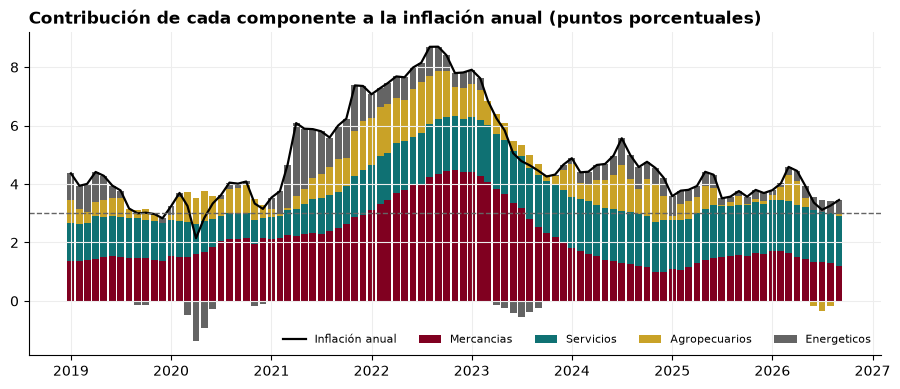

Residuo máximo: 0.005 puntos porcentuales


,mercancias,servicios,agropecuarios,energeticos,total,residuo
fecha,,,,,,
2026-06-01,1.34,1.77,-0.18,0.43,3.37,-0.0
2026-07-01,1.33,1.72,-0.34,0.41,3.12,0.0
2026-08-01,1.29,1.72,-0.16,0.41,3.26,-0.0
2026-09-01,1.21,1.69,0.08,0.47,3.45,-0.0


In [7]:
aportes = bmx.contribuciones_inflacion("2019-01-01")
componentes = ["mercancias", "servicios", "agropecuarios", "energeticos"]

fig, ax = plt.subplots(figsize=(11, 4.2))
positivo = aportes[componentes].clip(lower=0).cumsum(axis=1).shift(axis=1, fill_value=0)
negativo = aportes[componentes].clip(upper=0).cumsum(axis=1).shift(axis=1, fill_value=0)
for k, col in enumerate(componentes):
    valores = aportes[col]
    base = positivo[col].where(valores >= 0, negativo[col])
    ax.bar(aportes.index, valores, bottom=base, width=25, color=sie.PALETA[k], label=col.capitalize())
ax.plot(aportes.index, aportes["total"], color="black", lw=1.6, label="Inflación anual")
ax.axhline(3, color=GRIS, ls="--", lw=1)
ax.set_title("Contribución de cada componente a la inflación anual (puntos porcentuales)")
ax.legend(ncols=5, fontsize=8)
plt.show()

print(f"Residuo máximo: {aportes['residuo'].abs().max():.3f} puntos porcentuales")
aportes.tail(4).round(2)

## 2. ¿Qué espera el mercado? Inflación implícita

Un **Bono M** paga una tasa nominal; un **Udibono** paga una tasa real más la inflación observada.
La inflación que deja indiferente a un inversionista entre ambos es

$$\pi^{impl} = \frac{1 + i}{1 + r} - 1$$

Banxico publica cada día el precio, el cupón y los días por vencer de los títulos de referencia,
pero no su rendimiento. `bmx.inflacion_implicita` lo calcula con la convención mexicana (cupones
cada 182 días, base 360) y devuelve las dos tasas y su diferencia.

In [8]:
bei = bmx.inflacion_implicita(10, INICIO)
bei.tail(5).round(3)

,nominal,real,implicita,plazo_nominal,plazo_real
fecha,,,,,
2026-10-26,9.360,4.86,4.291,9.322,10.491
2026-10-27,9.360,4.93,4.222,9.320,10.489
2026-10-28,9.336,4.92,4.209,9.317,10.486
2026-10-29,9.290,4.92,4.165,9.314,10.483
2026-10-30,9.249,4.89,4.156,9.311,10.480


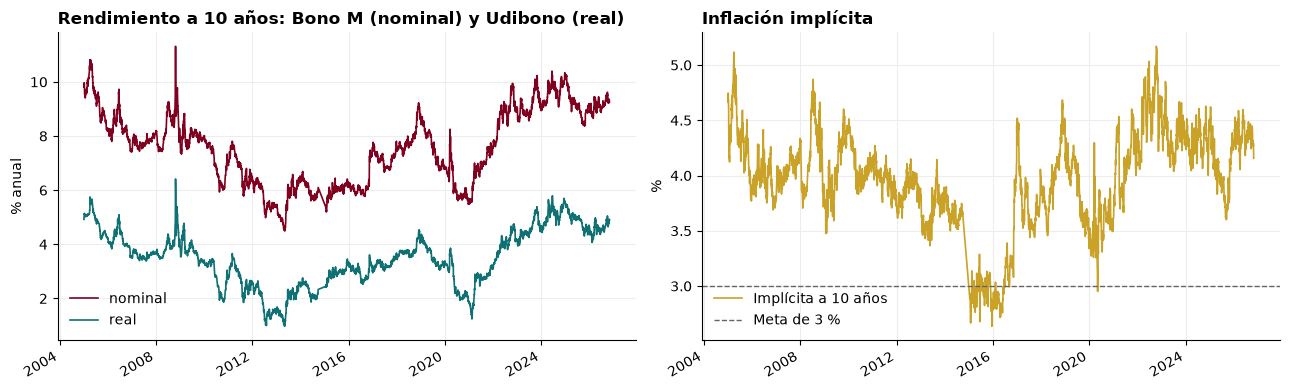

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

bei[['nominal', 'real']].plot(ax=ax[0], color=[GUINDA, TEAL], lw=1.2)
ax[0].set_title('Rendimiento a 10 años: Bono M (nominal) y Udibono (real)')
ax[0].set_ylabel('% anual'); ax[0].set_xlabel('')

bei['implicita'].plot(ax=ax[1], color=OCRE, lw=1.2, label='Implícita a 10 años')
ax[1].axhline(3, color=GRIS, ls='--', lw=1, label='Meta de 3 %')
ax[1].set_title('Inflación implícita')
ax[1].set_ylabel('%'); ax[1].set_xlabel(''); ax[1].legend()

plt.tight_layout(); plt.show()

### No es una expectativa pura

La implícita incluye una **prima por riesgo inflacionario** (la sube) y una **prima de liquidez** de
los Udibonos (la baja); Banxico la llama *compensación por inflación y riesgo inflacionario*. Además,
los dos títulos de referencia rara vez vencen el mismo día (columnas `plazo_nominal` y `plazo_real`),
y el vector de precios tiene meses sin datos y saltos cuando cambia el título de referencia.

Por eso conviene ponerla junto a lo que responden los especialistas en la encuesta de Banxico.

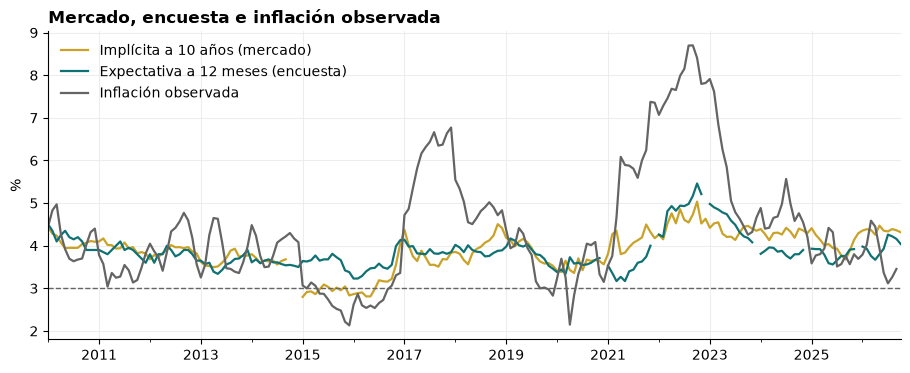

,Implícita a 10 años (mercado),Expectativa a 12 meses (encuesta),Inflación observada
fecha,,,
2026-06-01,4.35,3.93,3.37
2026-07-01,4.34,4.26,3.12
2026-08-01,4.39,4.22,3.26
2026-09-01,4.36,4.16,3.45


In [10]:
encuesta = bmx.serie('expectativa_inflacion_12m', INICIO)
observada = sie.variacion_anual(indices['inpc'])

comparacion = pd.DataFrame({
    'Implícita a 10 años (mercado)'  : sie.a_mensual(bei['implicita'], 'promedio'),
    'Expectativa a 12 meses (encuesta)': encuesta,
    'Inflación observada'            : observada,
}).loc['2010':]

ax = comparacion.plot(color=[OCRE, TEAL, GRIS], lw=1.6)
ax.axhline(3, color=GRIS, ls='--', lw=1)
ax.set_title('Mercado, encuesta e inflación observada')
ax.set_ylabel('%'); ax.set_xlabel('')
plt.show()

comparacion.dropna().tail(4).round(2)

### Curva de implícitas e implícita forward

Con varios plazos se obtiene la inflación que el mercado descuenta para un periodo **futuro**. La
de 10 años dentro de 10 años («10a10a») deja fuera los choques de corto plazo y es una lectura más
limpia del anclaje de largo plazo. Es una aproximación: supone que los títulos vencen exactamente a
10 y 20 años, y el Bono M del grupo «10 a 20 años» suele ser más corto.

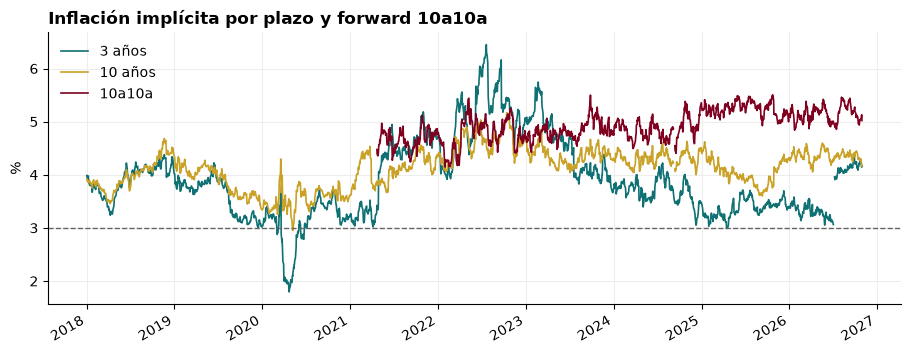

,3,10,20,30,10a10a
fecha,,,,,
2026-10-28,4.17,4.21,4.65,4.77,5.09
2026-10-29,4.14,4.17,4.65,4.77,5.13
2026-10-30,4.16,4.16,4.59,4.75,5.02


In [11]:
RECIENTE = '2018-01-01'
curva = pd.DataFrame({plazo: bmx.inflacion_implicita(plazo, RECIENTE)['implicita']
                      for plazo in (3, 10, 20, 30)})
curva['10a10a'] = sie.inflacion_implicita_forward(curva[10], curva[20], 10, 20)

ax = curva[[3, 10, '10a10a']].rename(columns={3: '3 años', 10: '10 años'}).plot(
    color=[TEAL, OCRE, GUINDA], lw=1.2)
ax.axhline(3, color=GRIS, ls='--', lw=1)
ax.set_title('Inflación implícita por plazo y forward 10a10a')
ax.set_ylabel('%'); ax.set_xlabel('')
plt.show()

curva.tail(3).round(2)

### La curva de rendimientos

Con los Cetes (28 a 364 días) y los Bonos M de referencia (hasta 30 años) se arma la curva de rendimientos del
día y se ajusta una curva de Nelson-Siegel, que permite leer la tasa a cualquier plazo. Son rendimientos a
vencimiento, no una curva cupón cero.

Fecha: 30/10/2026  |  CurvaNS(nivel=9.762, pendiente=-3.332, curvatura=3.865, lam=5.66, error=0.038)


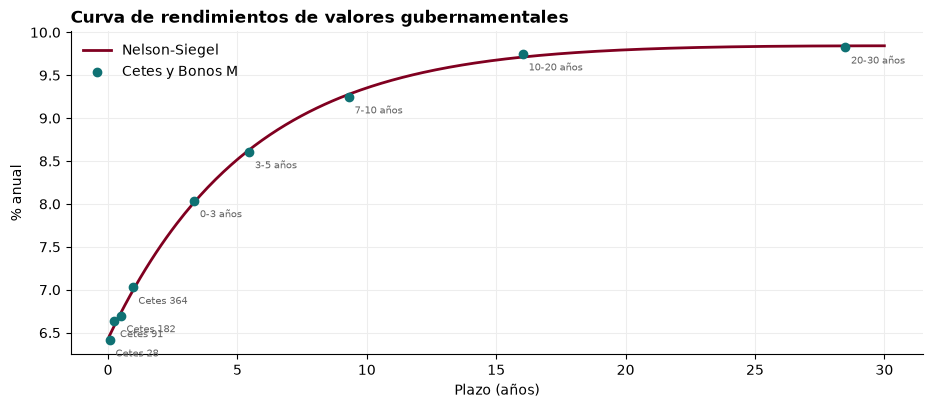

In [12]:
curva = bmx.curva_rendimientos()
ns = curva.attrs["curva"]
print(f"Fecha: {curva.attrs['fecha']:%d/%m/%Y}  |  {ns}")

plazos = np.linspace(0.05, 30, 300)
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(plazos, ns(plazos), color=GUINDA, lw=2, label="Nelson-Siegel")
ax.scatter(curva["plazo"], curva["rendimiento"], color=TEAL, zorder=3, label="Cetes y Bonos M")
for _, fila in curva.iterrows():
    ax.annotate(fila["titulo"].replace("Bono M ", ""), (fila["plazo"], fila["rendimiento"]),
                textcoords="offset points", xytext=(4, -12), fontsize=7, color=GRIS)
ax.set_title("Curva de rendimientos de valores gubernamentales")
ax.set_xlabel("Plazo (años)"); ax.set_ylabel("% anual"); ax.legend()
plt.show()

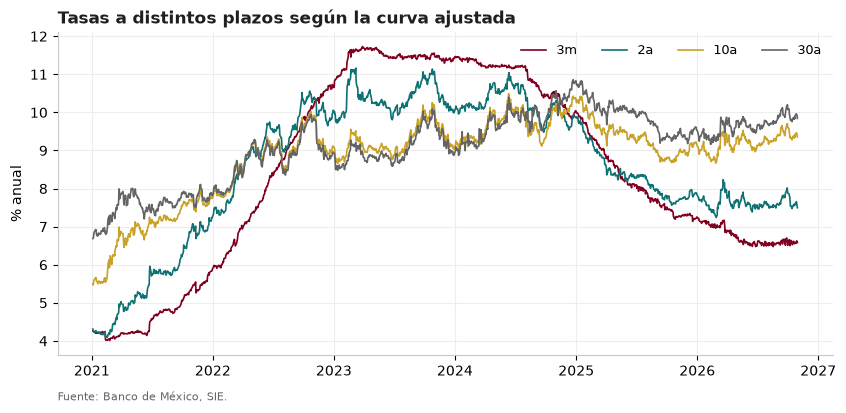

In [13]:
historia = bmx.curva_historica("2021-01-01")
sie.graficar(historia[["3m", "2a", "10a", "30a"]], "Tasas a distintos plazos según la curva ajustada",
             unidad="% anual", lw=1.2);

### Tasa real: ex-post, ex-ante y de mercado

Tres respuestas distintas a «¿cuál es la tasa real?»: descontando la inflación ya observada,
descontando la esperada, o leyendo directamente el rendimiento del Udibono.

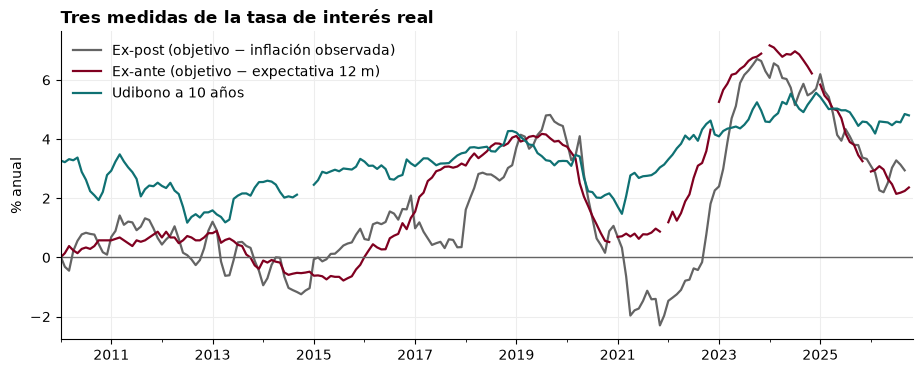

In [14]:
objetivo = sie.a_mensual(bmx.serie('tasa_objetivo', INICIO), 'promedio')

reales = pd.DataFrame({
    'Ex-post (objetivo − inflación observada)': sie.tasa_real(objetivo, observada),
    'Ex-ante (objetivo − expectativa 12 m)'   : sie.tasa_real(objetivo, encuesta),
    'Udibono a 10 años'                       : sie.a_mensual(bei['real'], 'promedio'),
}).loc['2010':]

ax = reales.plot(color=[GRIS, GUINDA, TEAL], lw=1.6)
ax.axhline(0, color=GRIS, lw=1)
ax.set_title('Tres medidas de la tasa de interés real')
ax.set_ylabel('% anual'); ax.set_xlabel('')
plt.show()

## 3. ¿Qué diría un modelo sencillo? Pronósticos de referencia

`pronosticar_inflacion` ajusta un SARIMA al logaritmo del INPC —por omisión el «modelo de
aerolíneas» $(0,1,1)(0,1,1)_{12}$— y simula trayectorias para obtener el intervalo de la inflación
**anual**, que depende de varios meses pronosticados a la vez.

In [15]:
inpc = indices['inpc'].dropna()
pronostico = sie.pronosticar_inflacion(inpc, horizonte=12, nivel=0.90)
pronostico.round(2)

,indice,mensual,anual,anual_inf,anual_sup
fecha,,,,,
2026-10-01,146.86,0.54,3.63,3.21,4.08
2026-11-01,147.81,0.65,3.62,2.92,4.36
2026-12-01,148.46,0.44,3.79,2.92,4.74
2027-01-01,149.28,0.55,3.96,2.90,5.10
2027-02-01,149.89,0.41,3.87,2.63,5.17
2027-03-01,150.65,0.51,3.50,2.14,4.95
2027-04-01,150.83,0.12,3.42,1.98,5.02
2027-05-01,150.74,-0.05,3.58,2.05,5.22
2027-06-01,151.06,0.21,4.09,2.44,5.89


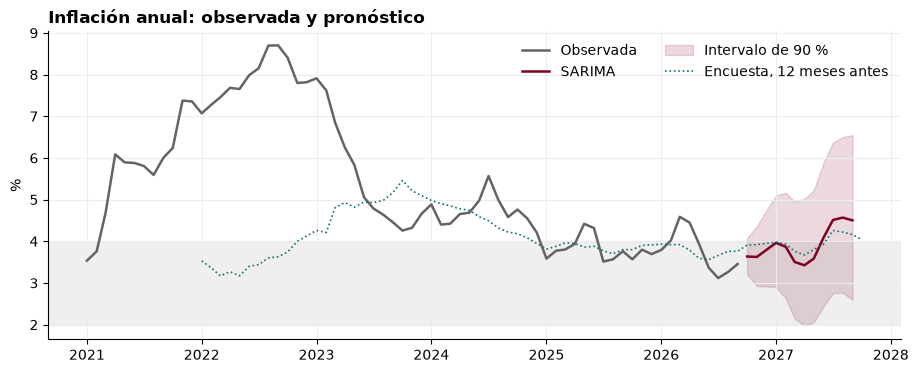

In [16]:
historia = sie.variacion_anual(inpc).loc['2021':]

fig, ax = plt.subplots()
ax.plot(historia, color=GRIS, lw=1.8, label='Observada')
ax.plot(pronostico['anual'], color=GUINDA, lw=1.8, label='SARIMA')
ax.fill_between(pronostico.index, pronostico['anual_inf'], pronostico['anual_sup'],
                color=GUINDA, alpha=.15, label='Intervalo de 90 %')
ax.plot(encuesta.loc['2021':].index + pd.DateOffset(months=12), encuesta.loc['2021':],
        color=TEAL, lw=1.2, ls=':', label='Encuesta, 12 meses antes')
ax.axhspan(2, 4, color=GRIS, alpha=.10)
ax.set_title('Inflación anual: observada y pronóstico')
ax.set_ylabel('%'); ax.legend(ncols=2)
plt.show()

### ¿Y sirve? Evaluación fuera de muestra

Un pronóstico solo vale lo que valió en el pasado. `evaluar_pronosticos` regresa en el tiempo,
estima el modelo **solo con lo que se conocía en cada fecha**, pronostica, y compara contra lo que
ocurrió. El rival es el método ingenuo: «la inflación anual se queda donde está».

In [17]:
evaluacion = sie.evaluar_pronosticos(inpc, horizontes=(1, 3, 6, 12), desde='2012-01-01', paso=3)
evaluacion['mejora_%'] = (1 - evaluacion['sarima'] / evaluacion['ingenuo']) * 100
evaluacion.round(3)

,sarima,ingenuo,n,mejora_%
horizonte,,,,
1,0.309,0.468,59,33.949
3,0.585,0.740,59,20.933
6,0.956,1.113,58,14.116
12,1.577,1.767,56,10.723


La tabla es la raíz del error cuadrático medio, en puntos porcentuales de inflación anual.
Dos lecturas honestas:

- El error **crece rápido con el horizonte**: a doce meses supera el punto porcentual, más que el
  ±1 del intervalo de variabilidad de Banxico.
- La ventaja sobre el método ingenuo es clara a un mes y **se diluye con el horizonte**. Es el
  resultado clásico de la literatura (Atkeson y Ohanian, 2001): a un año es difícil ganarle a
  «la inflación seguirá como está».

El intervalo del pronóstico solo refleja choques futuros bajo el modelo; no incluye la incertidumbre
de los parámetros ni la de haber elegido mal el modelo.

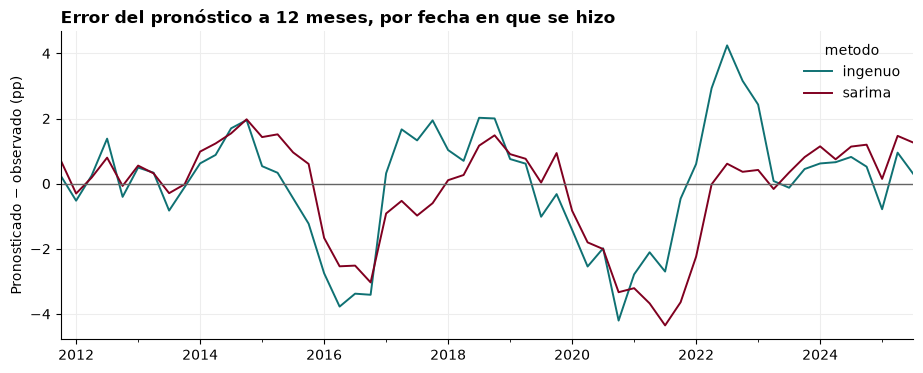

In [18]:
errores = evaluacion.attrs['errores']
doce = errores[errores['horizonte'] == 12].pivot(index='origen', columns='metodo', values='error')

ax = doce.plot(color=[TEAL, GUINDA], lw=1.4)
ax.axhline(0, color=GRIS, lw=1)
ax.set_title('Error del pronóstico a 12 meses, por fecha en que se hizo')
ax.set_ylabel('Pronosticado − observado (pp)'); ax.set_xlabel('')
plt.show()